<a href="https://colab.research.google.com/github/monikaly13/TGI_Friday_Class/blob/main/assignment05_ASB2T4_LY_Monika_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root="./data", train=True,  download=True, transform=transform)
test_set  = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=64, shuffle=False)

classes = train_set.classes
print(classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN().to(device)
print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    running_loss, correct, total = 0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch+1}/{EPOCHS} - loss: {running_loss/total:.4f} - accuracy: {correct/total:.4f}")

Epoch 1/20 - loss: 1.4832 - accuracy: 0.4567
Epoch 2/20 - loss: 1.0960 - accuracy: 0.6100
Epoch 3/20 - loss: 0.9323 - accuracy: 0.6718
Epoch 4/20 - loss: 0.8143 - accuracy: 0.7141
Epoch 5/20 - loss: 0.7365 - accuracy: 0.7424
Epoch 6/20 - loss: 0.6655 - accuracy: 0.7656
Epoch 7/20 - loss: 0.6015 - accuracy: 0.7881
Epoch 8/20 - loss: 0.5490 - accuracy: 0.8066
Epoch 9/20 - loss: 0.5011 - accuracy: 0.8211
Epoch 10/20 - loss: 0.4598 - accuracy: 0.8363
Epoch 11/20 - loss: 0.4227 - accuracy: 0.8477
Epoch 12/20 - loss: 0.3892 - accuracy: 0.8594
Epoch 13/20 - loss: 0.3648 - accuracy: 0.8685
Epoch 14/20 - loss: 0.3421 - accuracy: 0.8767
Epoch 15/20 - loss: 0.3180 - accuracy: 0.8849
Epoch 16/20 - loss: 0.2982 - accuracy: 0.8923
Epoch 17/20 - loss: 0.2882 - accuracy: 0.8947
Epoch 18/20 - loss: 0.2677 - accuracy: 0.9025
Epoch 19/20 - loss: 0.2644 - accuracy: 0.9021
Epoch 20/20 - loss: 0.2369 - accuracy: 0.9132


In [ ]:
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {100 * correct / total:.2f}%")

Test accuracy: 77.29%


In [ ]:
torch.save(model.state_dict(), "cnn_cifar10.pth")
print("Model saved!")

Model saved!


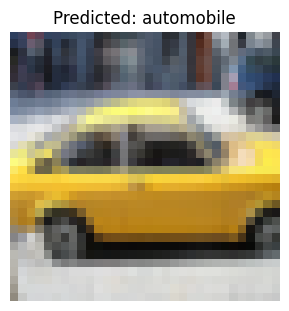

True class: automobile


In [ ]:
def show_random_prediction():
    idx = random.randrange(len(test_set))
    image, true_label = test_set[idx]

    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))
        pred = output.argmax(1).item()

    img = image / 2 + 0.5                      # undo normalization
    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(img.permute(1, 2, 0))
    plt.title(f"Predicted: {classes[pred]}")
    plt.axis("off")
    plt.show()
    print("True class:", classes[true_label])

show_random_prediction()

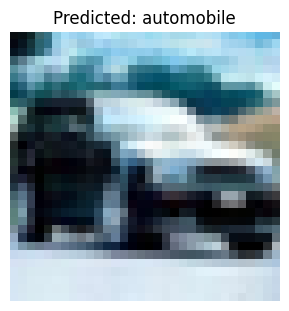

True class: automobile


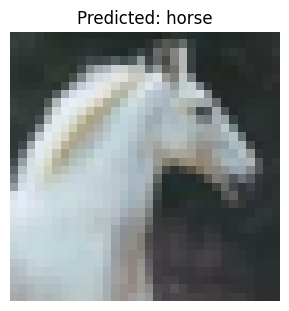

True class: horse


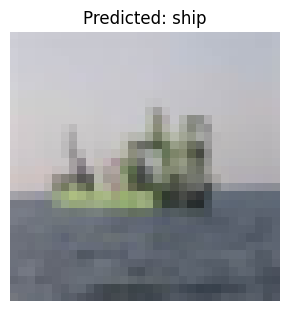

True class: ship


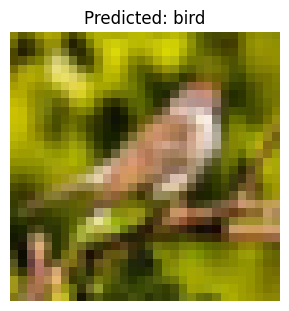

True class: bird


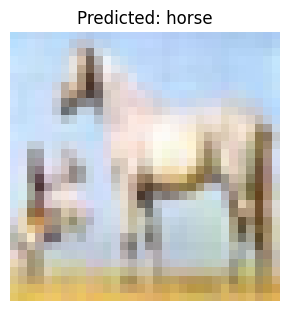

True class: horse


In [ ]:
for _ in range(10):
    show_random_prediction()